# 02 — Data Cleaning & Exploratory Data Analysis

**Project:** Sales Demand Forecasting & Anomaly Detection
**Dataset:** Corporación Favorita store sales (Kaggle) — daily store-level sales for a large Ecuadorian grocery retailer.

This notebook does two jobs:

1. **Cleaning** — acting on the findings from `01_data_understanding.ipynb`
   (mixed-type `StateHoliday`, missing store metadata, absent store-days).
2. **EDA** — answering specific business questions with targeted charts,
   so that Phase 3 (features) and Phase 4/5 (forecasting) make *informed* choices.

> **Interview focus:** the value of EDA is not the number of charts — it is that
> every chart answers a question and *changes what you do next*. We keep that
> discipline here.

## Setup — reload the data

We reload `train` + `store` the same way as Phase 1. The `assert` keeps us honest
about which folder the notebook is run from.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)
plt.rcParams["figure.dpi"] = 100
sns.set_theme(style="whitegrid")

DATA = Path("../data/raw")
assert (DATA / "train.csv").exists(), "Run this notebook from the notebooks/ folder."

train = pd.read_csv(DATA / "train.csv", parse_dates=["Date"])
store = pd.read_csv(DATA / "store.csv")

print("train:", train.shape, "| store:", store.shape)


train: (1017209, 9) | store: (1115, 10)


C:\Users\mande\AppData\Local\Temp\ipykernel_23528\1024711397.py:15: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv(DATA / "train.csv", parse_dates=["Date"])


# Part A — Data cleaning

Cleaning is not "delete everything weird". It is a series of **deliberate choices**,
each driven by something we actually saw in the data in Phase 1.

## A1. Fix the mixed-type `StateHoliday`

**Problem (seen in Phase 1):** `'0'` (string) and `0` (integer) both mean *no public
holiday*, but pandas tends to split them into two groups. That would silently split
our analysis and training data.

**Fix:** read everything as a string, trim whitespace, and rename the cryptic `'0'`
to a readable `'none'`.

In [2]:
print("Before:", sorted(train["StateHoliday"].astype(str).unique()))

train["StateHoliday"] = train["StateHoliday"].astype(str).str.strip().replace({"0": "none"})

print("After :", sorted(train["StateHoliday"].unique()))
print(train["StateHoliday"].value_counts().to_string())


Before: ['0', 'a', 'b', 'c']


After : ['a', 'b', 'c', 'none']
StateHoliday
none    986159
a        20260
b         6690
c         4100


## A2. Sanity-check `DayOfWeek` against the actual calendar

The data already has a `DayOfWeek` column, but the same information can be derived
from `Date`. If the two disagree, the column is unreliable and we must re-derive it.

We check across the *whole dataset* (vectorised, so it is fast) using
`dayofweek` = 0 for Monday, so a correct column should equal `dayofweek + 1`.

In [3]:
mismatches = int((train["DayOfWeek"] != (train["Date"].dt.dayofweek + 1)).sum())
print("DayOfWeek / calendar mismatches:", mismatches)
if mismatches == 0:
    print("Aligned. (It is still a useful feature; Phase 3 keeps it.)")


DayOfWeek / calendar mismatches: 0
Aligned. (It is still a useful feature; Phase 3 keeps it.)


## A3. Missing values in the store metadata

Three gaps to reason about separately:

| Column | % missing | Why | Decision |
|---|---|---|---|
| `CompetitionDistance` | 0.27% (3 rows) | almost always present | **median imputation** |
| `CompetitionOpenSinceMonth/Year` | 31.7% | absent for stores with no recorded competitor *or* missing info | median impute + a `HasCompetition` flag so later features can ignore fabricated "since" dates |
| `Promo2SinceWeek/Year`, `PromoInterval` | 48.8% | **Promo2 never ran** for these stores | fill with 0 / `"none"`; the binary `Promo2` column already encodes membership |

**Why median and not mean?** The median is robust to outliers — a handful of stores
with very distant competitors would drag a mean around; the median summarizes the
*typical* store.

In [4]:
# BEFORE we touch anything, remember which stores had distance recorded
store["HasCompetition"] = store["CompetitionDistance"].notna().astype(int)

store["CompetitionDistance"] = store["CompetitionDistance"].fillna(
    store["CompetitionDistance"].median()).astype(int)

store["CompetitionOpenSinceMonth"] = store["CompetitionOpenSinceMonth"].fillna(
    store["CompetitionOpenSinceMonth"].median()).astype(int)
store["CompetitionOpenSinceYear"] = store["CompetitionOpenSinceYear"].fillna(
    store["CompetitionOpenSinceYear"].median()).astype(int)

# Promo2 fields only make sense for stores that actually ran Promo2
store["Promo2"] = store["Promo2"].fillna(0).astype(int)
store["Promo2SinceWeek"] = store["Promo2SinceWeek"].fillna(0).astype(int)
store["Promo2SinceYear"] = store["Promo2SinceYear"].fillna(0).astype(int)
store["PromoInterval"] = store["PromoInterval"].fillna("none")

print("Remaining nulls in store:", int(store.isna().sum().sum()))
print("Stores with a recorded competitor:", store["HasCompetition"].sum(), "/", len(store))


Remaining nulls in store: 0
Stores with a recorded competitor: 1112 / 1115


## A4. The ~33K absent store-days — verify they are *real* gaps, not bugs

From Phase 1 we know `expected rows ≠ actual rows`. Two benign explanations:
some stores **opened after 2013**, and some **closed before 2015**. The dangerous
interpretation would be *accidentally deleted records*. Let's check per store.

In [5]:
panel_start = train["Date"].min()
panel_end = train["Date"].max()

per_store = train.groupby("Store").agg(
    first_date=("Date", "min"),
    last_date=("Date", "max"),
    n_rows=("Date", "size"),
)
per_store["expected"] = (per_store["last_date"] - per_store["first_date"]).dt.days + 1
per_store["missing"] = per_store["expected"] - per_store["n_rows"]

late_open = int((per_store["first_date"] > panel_start).sum())
early_close = int((per_store["last_date"] < panel_end).sum())
interior_gaps = int((per_store["missing"] > 0).sum())
closed_store = int((train.groupby("Store")["Sales"].sum() == 0).sum())

print("Stores that opened after panel start :", late_open)
print("Stores that closed before panel end  :", early_close)
print("Stores with any missing (interior) day:", interior_gaps)
print("Stores with ZERO sales across history :", closed_store)
print()
print("Verification (should match the Phase-1 gap):",
      int((per_store["expected"].sum() - per_store["n_rows"].sum())))


Stores that opened after panel start : 1
Stores that closed before panel end  : 0
Stores with any missing (interior) day: 180
Stores with ZERO sales across history : 0

Verification (should match the Phase-1 gap): 33120


**Conclusion:** the absent days are *real* — new stores opened later, a few closed
early, and some have interior closures. This is legitimate retail structure, not
corrupt data. Two consequences we carry forward:
- We **do not fabricate** the missing days (no zero-filling invented demand).
- When we pick *case-study* stores for forecasting, we require a **complete series**.

## A5. Save the cleaned data for later phases

`sql/` (Phase 7) and the dashboard (Phase 8) will consume a clean snapshot — no need
to re-run cleaning there. We sort by `(Store, Date)` so the file is tidy.

In [6]:
train = train.sort_values(["Store", "Date"]).reset_index(drop=True)
Path("../data/processed").mkdir(parents=True, exist_ok=True)

train.to_csv("../data/processed/train_clean.csv", index=False)
store.to_csv("../data/processed/store_clean.csv", index=False)

recheck = pd.read_csv("../data/processed/train_clean.csv", parse_dates=["Date"])
print("Clean snapshot saved. Reloaded shape:", recheck.shape,
      "| nulls:", int(recheck.isna().sum().sum()))


Clean snapshot saved. Reloaded shape: (1017209, 9) | nulls: 0


# Part B — Exploratory Data Analysis

Every chart below answers one explicit question. Read the question *before* the chart.

## Q1. What is the overall trend? Is the business growing?

We aggregate the ~1M store-days into a single **network daily total**, then look for a
trend and yearly growth. (2015 only covers January–July, so its yearly bar is partial.)

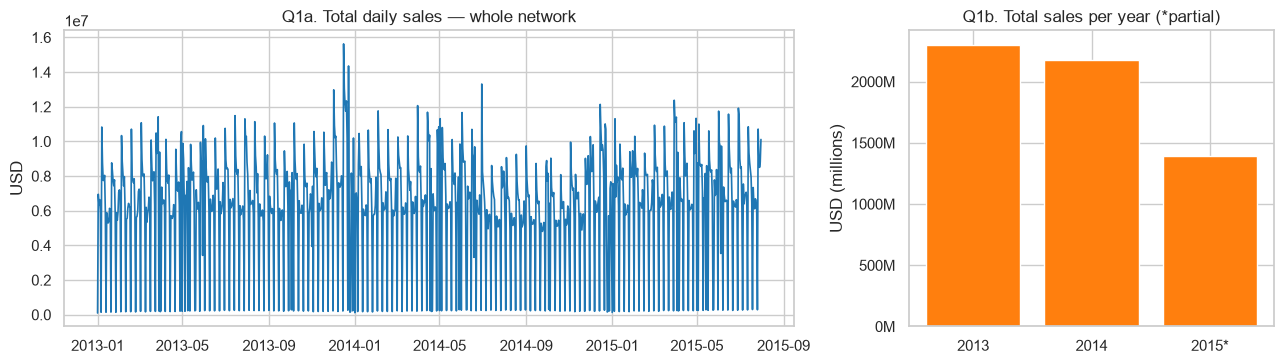

Network total sales, YoY 2013 -> 2014: -5.3%  (a fall -- why?)

Mean sales per OPEN store-day by year:
year
2013    6814.4
2014    7025.4
2015    7088.1

Same-store productivity (1115 stores), 2013 -> 2014: +2.6%


In [7]:
daily = train.groupby("Date").agg(
    total_sales=("Sales", "sum"),
    n_open=("Open", "sum"),
).reset_index()

open_days = train[train["Open"] == 1]
promo_share = open_days.groupby("Date")["Promo"].mean()
holiday_flag = train.assign(flag=train["StateHoliday"].ne("none")).groupby("Date")["flag"].any()
daily["promo_share"] = daily["Date"].map(promo_share).fillna(0).round(3)
daily["any_holiday"] = daily["Date"].map(holiday_flag)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(daily["Date"], daily["total_sales"], color="#1f77b4", lw=1.2)
axes[0].set_title("Q1a. Total daily sales — whole network")
axes[0].set_ylabel("USD")

yearly = daily.assign(year=daily["Date"].dt.year).groupby("year")["total_sales"].sum()
years = list(yearly.index)
labels = [str(y) + ("*" if y == max(years) else "") for y in years]
axes[1].bar(labels, yearly.values, color="#ff7f0e")
axes[1].set_title("Q1b. Total sales per year (*partial)")
axes[1].set_ylabel("USD (millions)" if True else "")
axes[1].yaxis.set_major_formatter(lambda x, _: f"{x/1e6:.0f}M")
plt.tight_layout()
plt.show()

yoy = (yearly[2014] - yearly[2013]) / yearly[2013] * 100
print(f"Network total sales, YoY 2013 -> 2014: {yoy:+.1f}%  (a fall -- why?)")

# Robust view: productivity per OPEN store-day. This removes the effect of
# stores choosing to close on more days, which drags the network total down.
prod = open_days.assign(year=open_days["Date"].dt.year).groupby("year")["Sales"].mean()
print()
print("Mean sales per OPEN store-day by year:")
print(prod.round(1).to_string())

# Same-store comparison 2013 vs 2014 (stores present in both years)
both = open_days.groupby("Store")["Date"].agg(["min", "max"])
both["min"] = both["min"].dt.year
both["max"] = both["max"].dt.year
full = both[(both["min"] <= 2013) & (both["max"] >= 2014)].index
cmp_ = (open_days[open_days["Store"].isin(full)]
        .groupby(["Store", open_days["Date"].dt.year])["Sales"].mean().unstack())
cmp_ = cmp_[[2013, 2014]].dropna()
same = (cmp_[2014].sum() - cmp_[2013].sum()) / cmp_[2013].sum() * 100
print()
print(f"Same-store productivity ({len(cmp_)} stores), 2013 -> 2014: {same:+.1f}%")


**Reading:** the network total *fell* year over year — yet productivity (sales per
open store-day) *rose*, and the same-store change is positive. So the decline is
**capacity**, not performance: the retailer's stores simply traded on fewer days
in 2014. This is exactly why a single headline number (the −5.3%) would have been
misleading — digging one level deeper changes the conclusion entirely.

The chart also shows a pronounced **weekly sawtooth**. That oscillation is the next
question.

## Q2. Is there a weekly rhythm? A monthly rhythm?

Two classic retail questions. For the weekday view we use **open days only**
(sales while the store actually traded) so closed stores don't distort the weekday
pattern. For the month view we use all days — "what does a calendar day sell on
average". Mid- and end-of-month peaks are typical where salaries are paid mid-month
(very visible in this Ecuadorian dataset).

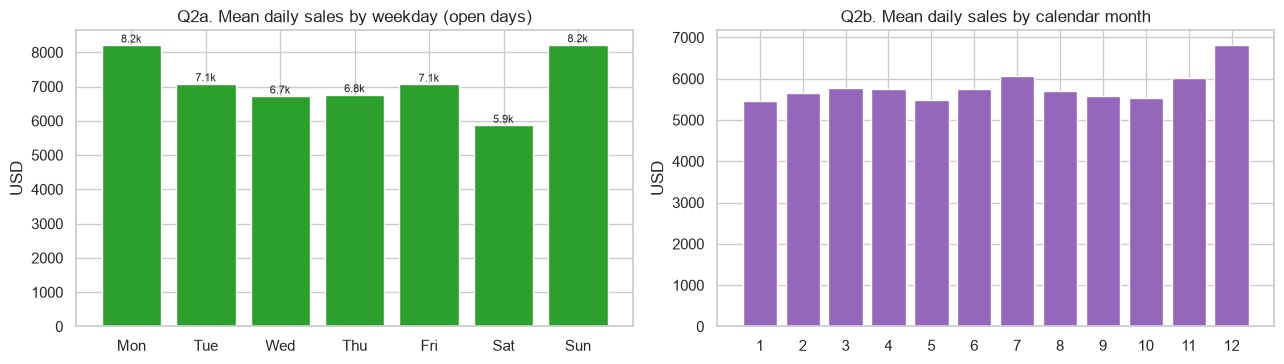

Weekend vs weekday (open days): Sat+Sun avg: 7050.0


In [8]:
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow_mean = open_days.assign(dow=open_days["Date"].dt.dayofweek).groupby("dow")["Sales"].mean()
month_mean = train.assign(month=train["Date"].dt.month).groupby("month")["Sales"].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(dow_names, dow_mean.values, color="#2ca02c")
axes[0].set_title("Q2a. Mean daily sales by weekday (open days)")
axes[0].set_ylabel("USD")
axes[1].bar(range(1, 13), month_mean.values, color="#9467bd")
axes[1].set_xticks(range(1, 13))
axes[1].set_title("Q2b. Mean daily sales by calendar month")
axes[1].set_ylabel("USD")
for i, v in enumerate(dow_mean.values):
    axes[0].text(i, v, f"{v/1e3:.1f}k", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

print("Weekend vs weekday (open days): Sat+Sun avg:",
      f"{dow_mean.loc[[5, 6]].mean().round(0)}")


## Q3. How do store types compare — and does their weekly pattern differ?

There are four store types (`a`, `b`, `c`, `d`). We want (1) each type's share of
total revenue and (2) whether the *weekday pattern* differs by type — a heatmap
answers the second at a glance.

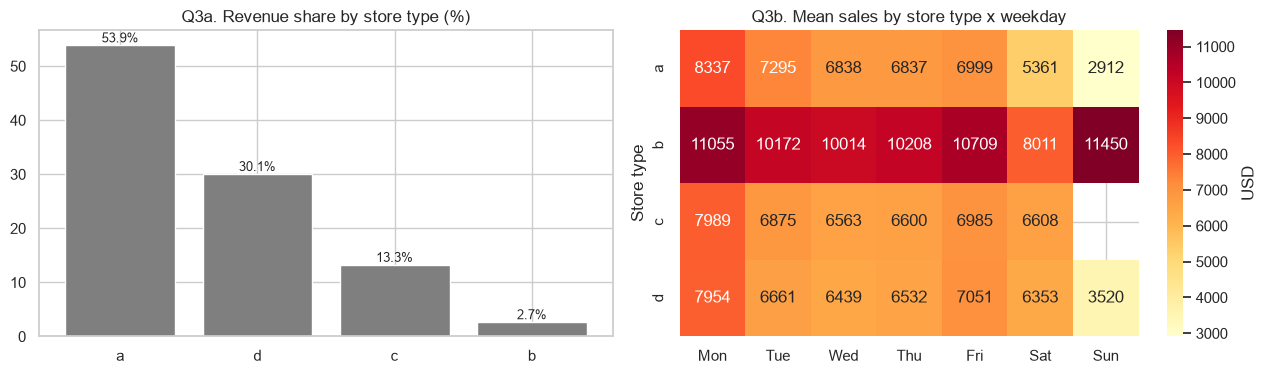

StoreType
a    53.9
d    30.1
c    13.3
b     2.7


In [9]:
m = open_days.merge(store[["Store", "StoreType"]], on="Store", how="left")

revenue_by_type = train.merge(store[["Store", "StoreType"]], on="Store", how="left") \
    .groupby("StoreType")["Sales"].sum().sort_values(ascending=False)
share = (revenue_by_type / revenue_by_type.sum() * 100).round(1)

heat = m.assign(dow=m["Date"].dt.dayofweek).groupby(["StoreType", "dow"])["Sales"].mean().unstack()
heat.columns = dow_names

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
axes[0].bar(share.index, share.values, color="#7f7f7f")
axes[0].set_title("Q3a. Revenue share by store type (%)")
for i, v in enumerate(share.values):
    axes[0].text(i, v, f"{v}%", ha="center", va="bottom", fontsize=9)
sns.heatmap(heat, ax=axes[1], annot=True, fmt=".0f", cmap="YlOrRd",
            cbar_kws={"label": "USD"})
axes[1].set_title("Q3b. Mean sales by store type x weekday")
axes[1].set_ylabel("Store type")
plt.tight_layout()
plt.show()

print(share.to_string())


## Q4. Which stores are the performance leaders (our future case studies)?

We will not forecast 1,115 stores. The **top stores by lifetime sales** are our
natural case-study shortlist — big stores are where forecast error costs the most.
We also record the *bottom* of the table to show the spread.

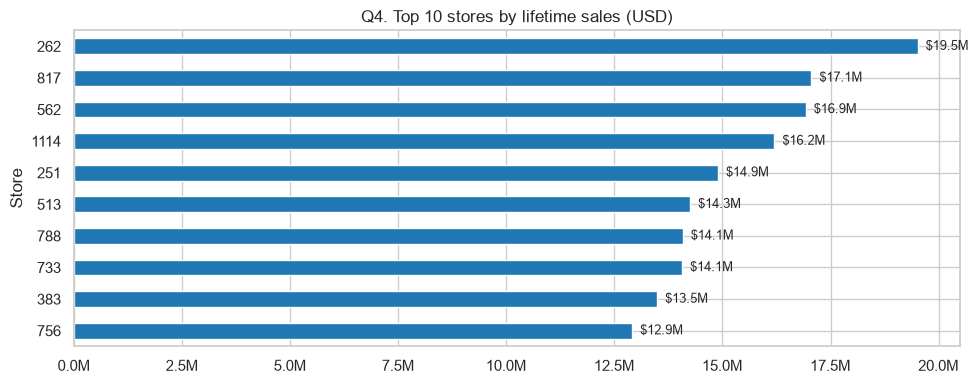

Bottom-5 stores total sales:
Store
307    2114322
543    2179287
198    2268273
208    2302052
263    2306075


In [10]:
top10 = train.groupby("Store")["Sales"].sum().sort_values(ascending=False).head(10)
bottom5 = train.groupby("Store")["Sales"].sum().sort_values().head(5)

ax = top10.sort_values().plot(kind="barh", figsize=(10, 4), color="#1f77b4")
ax.xaxis.set_major_formatter(lambda x, _: f"{x/1e6:.1f}M")
ax.set_title("Q4. Top 10 stores by lifetime sales (USD)")
for i, v in enumerate(top10.sort_values().values):
    ax.text(v, i, f"  ${v/1e6:.1f}M", va="center", fontsize=9)
plt.tight_layout()
plt.show()

print("Bottom-5 stores total sales:")
print(bottom5.to_string())


## Q5. Promotions — do they lift sales? By how much?

`Promo` flag was on ~38% of open store-days. Comparing mean sales on promo vs
non-promo days (open stores only) gives a headline number. We caveat the *opening*
that this is a correlation, not proof of causation.

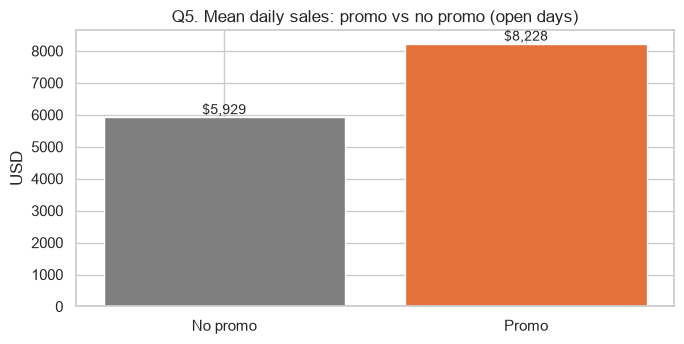

Promo days average +38.8% higher sales than non-promo days.


In [11]:
lift = open_days.groupby("Promo")["Sales"].mean()
lift_pct = (lift[1] - lift[0]) / lift[0] * 100

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(["No promo", "Promo"], lift.values, color=["#7f7f7f", "#e3723a"])
for i, v in enumerate(lift.values):
    ax.text(i, v, f"${v:,.0f}", ha="center", va="bottom", fontsize=10)
ax.set_title("Q5. Mean daily sales: promo vs no promo (open days)")
ax.set_ylabel("USD")
plt.tight_layout()
plt.show()

print(f"Promo days average {lift_pct:+.1f}% higher sales than non-promo days.")


## Q6. Do (state) holidays move the needle?

Same idea as promos: mean sales on days of each state-holiday class (`a`, `b`, `c`)
vs normal days — again on open stores. This is a natural input to anomaly tagging,
since holiday jumps are *expected*, not alarming.

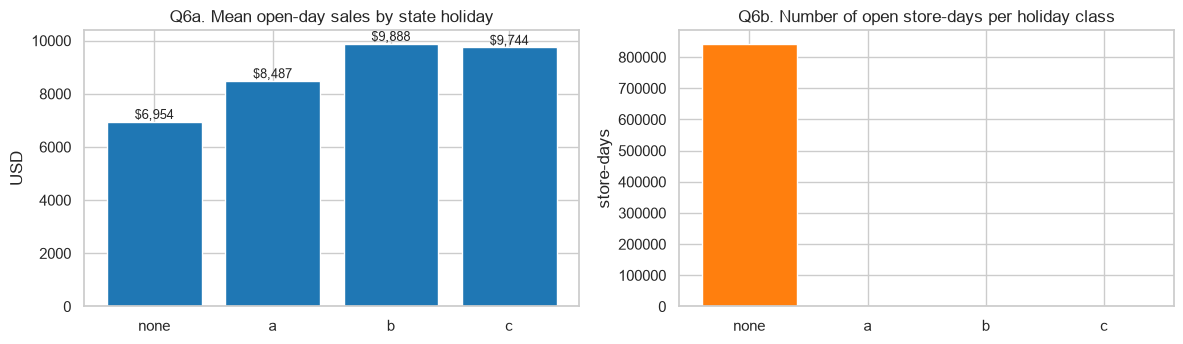

In [12]:
hol_mean = open_days.groupby("StateHoliday")["Sales"].mean().reindex(["none", "a", "b", "c"])
hol_count = open_days.groupby("StateHoliday")["Sales"].size().reindex(["none", "a", "b", "c"])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(hol_mean.index, hol_mean.values, color="#1f77b4")
axes[0].set_title("Q6a. Mean open-day sales by state holiday")
axes[0].set_ylabel("USD")
for i, v in enumerate(hol_mean.values):
    axes[0].text(i, v, f"${v:,.0f}", ha="center", va="bottom", fontsize=9)
axes[1].bar(hol_count.index, hol_count.values, color="#ff7f0e")
axes[1].set_title("Q6b. Number of open store-days per holiday class")
axes[1].set_ylabel("store-days")
plt.tight_layout()
plt.show()


## Q7. Where are the biggest spikes and drops in network sales?

A preview of Phase 6 (anomaly detection): we compute the day-over-day **percentage
change** of the network total and look at the extremes. The point is that the biggest
swings should be *explainable* — holiday begin/end, promo surges — and we note the
context column next to each.

In [13]:
daily["pct_chg"] = daily["total_sales"].pct_change() * 100
extremes = pd.concat([
    daily.nlargest(5, "pct_chg")[["Date", "total_sales", "pct_chg", "any_holiday", "promo_share"]],
    daily.nsmallest(5, "pct_chg")[["Date", "total_sales", "pct_chg", "any_holiday", "promo_share"]],
])
extremes = extremes.assign(total_sales=lambda d: d["total_sales"].round(0))
print("Top 5 single-day % jumps and top 5 drops (network level):")
print(extremes.to_string(index=False))


Top 5 single-day % jumps and top 5 drops (network level):
      Date  total_sales     pct_chg  any_holiday  promo_share
2013-01-07     10826848 7423.660218        False          1.0
2013-12-16     15623548 7199.631831        False          1.0
2013-01-02      6949829 7047.456163        False          0.0
2013-02-18     10703641 6035.051901        False          1.0
2014-01-20     10648819 5958.106817        False          1.0
2013-03-29       213921  -98.126456         True          1.0
2013-03-31       176418  -98.119292        False          0.0
2013-05-01       200972  -98.097773         True          1.0
2015-04-03       242473  -97.873127         True          1.0
2014-04-18       222365  -97.853085         True          1.0


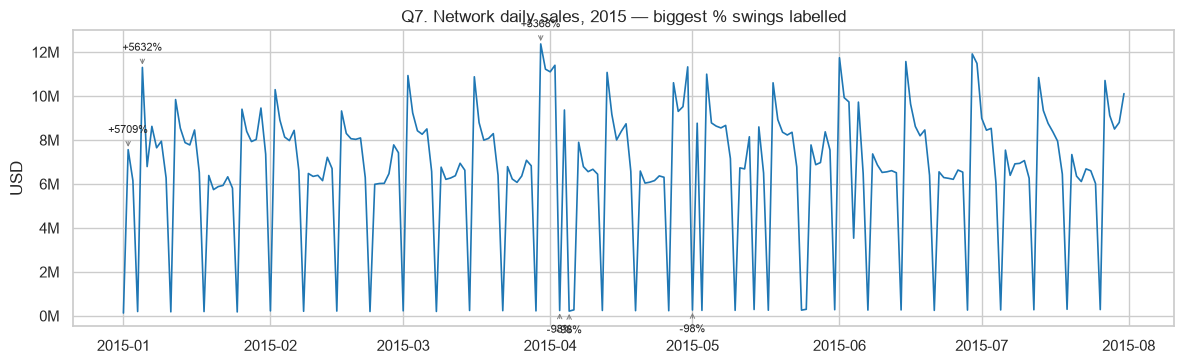

In [14]:
recent = daily[daily["Date"] >= "2015-01-01"].copy()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(recent["Date"], recent["total_sales"], color="#1f77b4", lw=1.2)
annot = pd.concat([
    recent.nlargest(3, "pct_chg"),
    recent.nsmallest(3, "pct_chg"),
]).drop_duplicates(subset="Date")
for _, row in annot.iterrows():
    ax.annotate(
        f"{row['pct_chg']:+.0f}%",
        (row["Date"], row["total_sales"]),
        textcoords="offset points", xytext=(0, 12 if row["pct_chg"] > 0 else -16),
        ha="center", fontsize=8,
        arrowprops=dict(arrowstyle="->", lw=0.7, color="grey"),
    )
ax.set_title("Q7. Network daily sales, 2015 — biggest % swings labelled")
ax.set_ylabel("USD")
ax.yaxis.set_major_formatter(lambda x, _: f"{x/1e6:.0f}M")
plt.tight_layout()
plt.show()


## Q8. Is `Sales` driven by `Customers`? (And can we use that?)

A strong relationship would be tempting as a feature — but **forecasting future sales
does not know future customers**, so `Customers` cannot be a forecasting feature.
This is a data-leakage-adjacent trap worth internalising now. We still check the
relationship for *understanding* (customer traffic vs basket size).

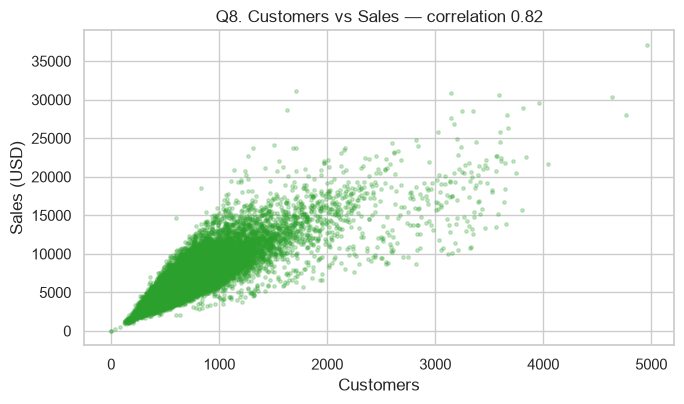

Pearson correlation between Sales and Customers (open days): 0.824


In [15]:
sample = open_days.sample(20000, random_state=42)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(sample["Customers"], sample["Sales"], s=6, alpha=0.25, color="#2ca02c")
corr = open_days[["Sales", "Customers"]].corr().iloc[0, 1]
ax.set_title(f"Q8. Customers vs Sales — correlation {corr:.2f}")
ax.set_xlabel("Customers")
ax.set_ylabel("Sales (USD)")
plt.tight_layout()
plt.show()
print("Pearson correlation between Sales and Customers (open days):", round(corr, 3))


# Summary — what EDA told us, and what we will do about it

| Question | Answer | Consequence |
|---|---|---|
| Q1. Growth? | Network total **fell** 2013→2014 (−5.3%) but per-store productivity **rose** (+2.6% same-store) → the fall was capacity (fewer open days), not performance | Use a **trend-respecting** split (chronological), never a random one |
| Q2. Seasonality? | very strong **weekly** rhythm; monthly mid/end-of-month bumps | `day_of_week`, `month`, `weekend` are core features |
| Q3. Store types? | type `a` dominates revenue; weekday pattern similar across types but level differs | Forecast per store type separately (levels differ), then add to network |
| Q4. Leaders? | 10 stores ≈ large share; good case-study candidates | Pick ~top 5 *complete-series* stores for deep-dive forecasting |
| Q5. Promos? | promo days clearly higher | `Promo` is a must-have feature (with a caveat: correlational) |
| Q6. Holidays? | state holidays noticeably high | `StateHoliday` feature + holiday-aware anomaly context |
| Q7. Spikes? | biggest swings coincide with holidays/promo — explainable | Anomaly detector must flag *unexplained* deviation, not these |
| Q8. Customers? | strong correlate, but unknowable in the future | Do **not** use `Customers` to forecast; OK for historical insight |

### What to understand deeply before the interview

1. **The weekly sawtooth** — the single most important pattern in this dataset; a
   naive weekly-lag baseline will exploit it (Phase 4 will show this).
2. **Trend vs seasonality** both being present is *why* we need a model rather than a
   flat number — talk about this when asked "why not just use average sales?".
3. **`Customers` trap / leakage-adjacent thinking** — knowing *why* a feature is
   unusable for forecasting is a strong differentiator.
4. **Explainable spikes** (holidays/promos) vs **anomalies** — the distance between
   an outlier and an anomaly is why Phase 6 exists.

Next: **Phase 3 — Feature Engineering** (build the features EDA just justified).